---
title: "Akita and Yoshida: gas holdup and kLa in bubble columns"
description: "The two papers behind the most quoted bubble-column correlations, checked against their own tables and one of their figures, and against each other: the 1974 interfacial area and kL multiplied together against the 1973 kLa."
categories: [sec:F, struct:S1, tier:T0, data:tier2, phase:gas-liquid]
date: 2026-11-19
---

# Akita and Yoshida: gas holdup and kLa in bubble columns

**Catalog ID:** `F1.1` · **Structures:** `S1` (algebraic closure) · **Tier:** T0

Most bubble-column models take their gas holdup and their volumetric mass-transfer
coefficient from two short papers by Akita and Yoshida. The 1973 paper correlates
the holdup and $k_La$ with the liquid properties and the column diameter; the 1974
paper splits $k_La$ into the interfacial area $a$ and the liquid-side coefficient
$k_L$, through a correlation for the mean bubble size. This page checks what can be
checked from what the two papers print: their tables, one figure, and whether the
second paper's pieces multiply back to the first paper's product.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "gallery-2026.11.28.2"  # replaced by the release tag at publication
PYMRM = ">=3.4.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "F1.1-akita-yoshida-bubble-column"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
# Imports. The page is algebra: it calls no pymrm operator and solves no PDE. pymrm
# contributes pymrm.checks.find_roots, which brackets every root the page reports.
import re
from dataclasses import dataclass, replace
from fractions import Fraction

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from pymrm.checks import find_roots
from gallery_utils import Claims, cite_data, load_claims, load_data, load_meta

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
claims = Claims(PAGE.split("-")[0])
F14 = "F1.4-krishna-ellenberger-holdup"
F13 = "F1.3-wilkinson-high-pressure-holdup"


def fill(text, **v):
    """Fill ``<<name:fmt>>`` in ``text`` from ``v``; ``pctN`` shows a fraction as a
    percentage with N decimals, ``+pctN`` with its sign."""
    def sub(m):
        name, _, fmt = m.group(1).partition(":")
        x = v[name]
        mp = re.fullmatch(r"(\+?)pct(\d+)", fmt)
        if mp:
            return f"{x * 100:{mp.group(1)}.{mp.group(2)}f} %"
        return format(x, fmt)
    return re.sub(r"<<([^<>]+)>>", sub, text)


def say(text, **v):
    """Prose whose numbers are written by code, so they cannot drift."""
    display(Markdown(fill(text, **v)))

## Background

A bubble column is a vertical vessel of liquid with gas sparged in at the bottom.
Two numbers decide most designs: the gas holdup $\varepsilon_G$, the volume
fraction of gas in the aerated liquid, and the volumetric liquid-side coefficient
$k_La$, which sets the rate of absorption. Akita and Yoshida measured both in
columns of 7.7 to 60 cm with water, aqueous glycol and glycerol, methanol, carbon
tetrachloride and a sodium sulfite solution, and fitted dimensionless power laws
whose exponents were chosen so that the holdup does not depend on the column
diameter and $k_La$ grows with it as $D^{0.17}$.

The 1974 paper photographed the bubbles, so that $k_La$ could be divided into the
area per volume $a = 6\varepsilon_G/d_{vs}$ and $k_L$. Its correlations for
$d_{vs}$, $a$ and $k_L$ are built on the 1973 holdup correlation, which makes the
two papers one system that should be consistent with itself.

## The published model

With $N_{Bo} = gD^2\rho_L/\gamma$, $N_{Ga} = gD^3/\nu_L^2$,
$N_{Fr} = U_G/\sqrt{gD}$ and $N_{Sc} = \nu_L/D_L$:

**Holdup** (1973, eq. 11):
$$\frac{\varepsilon_G}{(1-\varepsilon_G)^4} = c_1\,N_{Bo}^{1/8}N_{Ga}^{1/12}N_{Fr},
\qquad c_1 = 0.20,\ \text{or } 0.25 \text{ for electrolyte solutions.}$$

**Volumetric coefficient** (1973, eq. 18, and its dimensional form eq. 17):
$$\frac{k_La\,D^2}{D_L} = c_2\,N_{Sc}^{0.5}N_{Bo}^{0.62}N_{Ga}^{0.31}\varepsilon_G^{1.1},
\qquad c_2 = 0.6 .$$

**Mean bubble size** (1974, eq. 19), **area** (eq. 21) and its explicit form (eq. 24):
$$\frac{d_{vs}}{D} = 26\,N_{Bo}^{-0.50}N_{Ga}^{-0.12}N_{Fr}^{-0.12},\qquad
a = \frac{6\varepsilon_G}{d_{vs}},\qquad
aD = \tfrac13 N_{Bo}^{0.5}N_{Ga}^{0.1}\varepsilon_G^{1.13}.$$
Eq. 24 combines eq. 19 and eq. 21 with eq. 23, a power-law stand-in for eq. 11 that
the paper uses for $\varepsilon_G < 0.14$:
$N_{Fr} = 8.887\,N_{Bo}^{-1/8}N_{Ga}^{-1/12}\varepsilon_G^{10/9}$.

**Liquid-side coefficient** (1974, eq. 32), with the bubble groups
$N'_{Bo} = gd_{vs}^2\rho_L/\gamma$, $N'_{Ga} = gd_{vs}^3/\nu_L^2$:
$$\frac{k_Ld_{vs}}{D_L} = 0.5\,N_{Sc}^{1/2}N_{Ga}'^{1/4}N_{Bo}'^{3/8}.$$

**Bubble size distribution** (1974, eqs. 2 to 9): from the moments $\mu_n'$ of a
counted distribution, $d_{vs} = \mu_3'/\mu_2'$; a log-normal fit gives
$\sigma^2 = \tfrac23\ln\mu_3' - \ln\mu_2'$ and $m = \tfrac32\ln\mu_2' - \tfrac23\ln\mu_3'$,
with $d_g = e^m$ and $d_{vs} = e^{m + 2.5\sigma^2}$.

## Parameters and assumptions

Every published constant is a row of `akita-yoshida-printed-numbers.csv`, read
from the page images, and sits in the one dictionary `K` that every function
takes. Fractions are kept as printed. The liquid properties are the 1974 Table II.
Gravity is the field `g` of the data container (standard gravity to three digits);
neither paper prints the value it used. Groups are evaluated in SI units.

In [3]:
PN = load_data("akita-yoshida-printed-numbers.csv", page=PAGE, dtype=str)
K = {r.name: float(Fraction(r.printed)) for r in PN.itertuples()}
PRINTED = dict(zip(PN.name, PN.printed))
MEANING = dict(zip(PN.name, PN.meaning))
display(PN[["name", "printed", "paper", "equation", "meaning"]].set_index("name"))

,printed,paper,equation,meaning
name,,,,
c1,0.20,1973,11,holdup coefficient: eps/(1-eps)^4 = c1 Bo^a Ga...
c1_electrolyte,0.25,1973,11,coefficient suggested for electrolyte solutions
a_Bo,1/8,1973,10-11,holdup exponent on the Bond number
b_Ga,1/12,1973,10-11,holdup exponent on the Galilei number
holdup_power,4,1973,8,power on (1 - eps) in the holdup group
c2,0.6,1973,18,kLa coefficient: kLa D^2/DL = c2 Sc^0.5 Bo^p G...
sc_exp,0.5,1973,14,kLa exponent on the Schmidt number
p_Bo,0.62,1973,17-18,kLa exponent on the Bond number
q_Ga,0.31,1973,17-18,kLa exponent on the Galilei number


## The data

Five files, each with a provenance sidecar:

- **1974 Table II**, the properties of eleven liquids.
- **1974 Table IV**, the counted size distribution of one run (glycol-O₂, run
  conditions printed below) with its moments and the $d_{vs}$, $d_g$ and $\sigma$ the paper
  computes from it. The glycol concentration is not stated, so no property row is
  assigned to it.
- **1973 Table II**, the ranges of the mass-transfer experiments: for each system
  the lowest and highest gas velocity and holdup, and the Froude, Bond, Galilei
  and Schmidt numbers. The holdup range is not a pair of runs; the page pairs the
  lowest holdup with the lowest velocity because holdup rises with velocity in
  every figure. The rows whose liquid appears at the same temperature in the
  1974 Table II carry its key.
- **1974 Figure 12**, calculated against observed $k_La$, the markers digitised at
  the native resolution of the scan, with the reading error stated in the sidecar.
- the printed constants above.

The 1973 holdup data are in figures with many overlapping markers of seven shapes,
and the one small figure of $k_La$ against diameter (Figure 8) has a single
labelled ordinate tick, so its decade cannot be calibrated. Neither was extracted.

In [4]:
PROPS = load_data("akita-yoshida-1974-table2-properties.csv", page=PAGE)
T4 = load_data("akita-yoshida-1974-table4-bubble-sizes.csv", page=PAGE, dtype=str)
T2 = load_data("akita-yoshida-1973-table2-ranges.csv", page=PAGE, dtype=str, keep_default_na=False)
F12 = load_data("akita-yoshida-1974-fig12.csv", page=PAGE)
for name in ("akita-yoshida-1974-table2-properties", "akita-yoshida-1974-table4-bubble-sizes",
             "akita-yoshida-1973-table2-ranges", "akita-yoshida-1974-fig12",
             "akita-yoshida-printed-numbers"):
    print(cite_data(load_meta(name + ".csv", page=PAGE)))
display(PROPS.set_index("key"))
display(Markdown(f"The Table IV run: {K['t4_D_cm']:g} cm column, "
                 f"{K['t4_UG_m_h']:g} m/h superficial gas velocity."))


@dataclass(frozen=True)
class Data:
    """The page's inputs. Tables read as strings keep the printed precision."""
    props: pd.DataFrame
    t4: pd.DataFrame
    t2: pd.DataFrame
    f12: pd.DataFrame
    g: float = 9.81


C = Data(PROPS, T4, T2, F12)

Akita, K.; Yoshida, F. (1974) — Industrial & Engineering Chemistry Process Design and Development 13(1) 84-91 — doi:10.1021/i260049a016 — page-image transcription
Akita, K.; Yoshida, F. (1974) — Industrial & Engineering Chemistry Process Design and Development 13(1) 84-91 — doi:10.1021/i260049a016 — page-image transcription
Akita, K.; Yoshida, F. (1973) — Industrial & Engineering Chemistry Process Design and Development 12(1) 76-80 — doi:10.1021/i260045a015 — page-image transcription
Akita, K.; Yoshida, F. (1974) — Industrial & Engineering Chemistry Process Design and Development 13(1) 84-91 — doi:10.1021/i260049a016 — digitised from Figure 12, journal page 90
Akita, K.; Yoshida, F. (1973, 1974) — Industrial & Engineering Chemistry Process Design and Development 12(1) 76-80; Industrial & Engineering Chemistry Process Design and Development 13(1) 84-91 — doi:10.1021/i260045a015, 10.1021/i260049a016 — page-image transcription


,liquid,temp_C,density_g_cm3,viscosity_cP,surface_tension_dyn_cm,diffusivity_O2_1e-5_cm2_s
key,,,,,,
water_10,Water,10,0.9997,1.3080,74.2,1.570
water_20,Water,20,0.9982,1.0050,72.8,2.100
water_40,Water,40,0.9923,0.6560,69.6,3.450
glycol_30,30% glycol solution,20,1.0450,2.4380,60.1,1.060
glycol_70,70% glycol solution,20,1.0950,8.1710,54.3,0.670
glycol_100,100% glycol solution,20,1.1210,21.1400,46.3,0.260
glycerol_25,25% glycerol solution,20,1.0680,1.3280,70.8,0.995
glycerol_45,45% glycerol solution,20,1.1180,5.2100,69.1,0.582
glycerol_65,65% glycerol solution,20,1.1650,14.4500,67.5,0.299


The Table IV run: 15 cm column, 46.2 m/h superficial gas velocity.

## PyMRM implementation

There is no pymrm model on this page: the correlations are closed forms. The
functions below take SI arguments and the dictionary `K`. The holdup of eq. 11 is
implicit in $\varepsilon_G$ and is solved with `pymrm.checks.find_roots`, which
scans the whole physical range and refines every sign change; the page raises
unless exactly one root is found. `study(K, C)` computes every number the page
reports except the two ratios to `F1.3` and `F1.4`, which are formed from its output;
the break table reruns all of it with one defect at a time.

In [5]:
def si_props(props, key):
    """(rho, nu, gamma, D_L) in SI from a 1974 Table II row."""
    r = props.set_index("key").loc[key]
    rho = r.density_g_cm3 * 1e3
    return (rho, r.viscosity_cP * 1e-3 / rho, r.surface_tension_dyn_cm * 1e-3,
            r["diffusivity_O2_1e-5_cm2_s"] * 1e-9)


def groups(D, rho, nu, gam, g):
    """Bond and Galilei numbers of the column."""
    return g * D**2 * rho / gam, g * D**3 / nu**2


def holdup_eq11(Bo, Ga, Fr, K, c1):
    """Gas holdup from eq. 11: the one root of eps/(1-eps)^n = c1 Bo^a Ga^b Fr."""
    rhs = c1 * Bo**K["a_Bo"] * Ga**K["b_Ga"] * Fr
    res = find_roots(lambda e: e / (1 - e)**K["holdup_power"] - rhs, 1e-9, 0.99,
                     n_scan=200, log=True)
    if len(res["roots"]) != 1:
        raise ValueError(f"eq. 11 has {len(res['roots'])} roots: {res['message']}")
    return res["roots"][0]


def kla_eq18(D, nu, DL, Bo, Ga, eps, K):
    """k_L a (1/s) from 1973 eq. 18."""
    return (K["c2"] * DL / D**2 * (nu / DL)**K["sc_exp"] * Bo**K["p_Bo"] * Ga**K["q_Ga"]
            * eps**K["eps_exp"])


def dvs_eq19(D, Bo, Ga, Fr, K):
    """Volume-surface mean bubble diameter (m) from 1974 eq. 19."""
    return D * K["c_dvs"] * Bo**K["p_dvs"] * Ga**K["q_dvs"] * Fr**K["r_dvs"]


def kl_eq32(d, rho, nu, gam, DL, g, K):
    """Liquid-side coefficient k_L (m/s) from 1974 eq. 32."""
    Bo_b, Ga_b = g * d**2 * rho / gam, g * d**3 / nu**2
    return K["c_kl"] * DL / d * (nu / DL)**K["sc_kl"] * Ga_b**K["ga_kl"] * Bo_b**K["bo_kl"]


def a_eq24(D, Bo, Ga, eps, K):
    """Interfacial area (1/m) from 1974 eq. 24."""
    return K["c_eq24"] / D * Bo**K["p_eq24"] * Ga**K["q_eq24"] * eps**K["e_eq24"]


def implied24(K):
    """Eq. 24 as eqs. 19, 21 and 23 give it before rounding: the replacements of
    c_eq24, p_eq24, q_eq24 and e_eq24."""
    return {"c_eq24": 6 / (K["c_dvs"] * K["c_eq23"]**K["r_dvs"]),
            "p_eq24": -(K["p_dvs"] + K["r_dvs"] * K["a_eq23"]),
            "q_eq24": -(K["q_dvs"] + K["r_dvs"] * K["b_eq23"]),
            "e_eq24": 1 - K["r_dvs"] * K["e_eq23"]}


def half_units(computed, printed):
    """|computed - printed| in half-units of the printed last digit (strings)."""
    s = str(printed).strip()
    unit = 10.0**-(len(s.split(".")[1]) if "." in s else 0)
    return abs(computed - float(s)) / (0.5 * unit)


def one_root(f, lo, hi, what, log=False):
    """The single root of ``f`` on [lo, hi]; raises otherwise."""
    res = find_roots(f, lo, hi, n_scan=400, log=log)
    if len(res["roots"]) != 1:
        raise ValueError(f"{what}: {len(res['roots'])} roots on [{lo}, {hi}]")
    return res["roots"][0]

In [6]:
def study(K, C):
    """Every number the page reports, as a dict; ``name__margin`` are the margins
    of counts decided against a threshold."""
    M = {}
    g = C.g
    # --- 1974 Table IV: recompute the distribution, its moments and its fit
    t = C.t4
    x, n = t.x_mm.astype(float).to_numpy(), t.n_bubbles.astype(float).to_numpy()
    N = n.sum()
    dF = n / N
    F = np.cumsum(dF)
    mu2, mu3 = np.sum(x**2 * dF), np.sum(x**3 * dF)
    sig2 = 2 / 3 * np.log(mu3) - np.log(mu2)
    m = 1.5 * np.log(mu2) - 2 / 3 * np.log(mu3)
    dvs, dg, sig = mu3 / mu2, np.exp(m), np.sqrt(sig2)
    M["t4_n_total"] = int(N)
    M["t4_mu2"], M["t4_mu3"] = mu2, mu3
    M["t4_dvs_mm"], M["t4_dg_mm"], M["t4_sigma"] = dvs, dg, sig
    M["t4_lognormal_dvs_identity"] = abs(np.exp(m + 2.5 * sig2) - dvs) / dvs
    hu = np.concatenate([[half_units(100 * a, b) for a, b in zip(dF, t.dF_pct)],
                         [half_units(100 * a, b) for a, b in zip(F, t.F_pct)],
                         [half_units(x_**2 * a, b) for x_, a, b in zip(x, dF, t.dmu2_mm2)],
                         [half_units(x_**3 * a, b) for x_, a, b in zip(x, dF, t.dmu3_mm3)]])
    M["t4_entries"] = int(hu.size)
    M["t4_entries_off"] = int(np.sum(hu > 2))
    M["t4_entries_off__margin"] = float(np.min(np.abs(hu - 2)) / 2)
    M["t4_entries_off_three_units"] = int(np.sum(hu > 6))
    M["t4_entries_off_three_units__margin"] = float(np.min(np.abs(hu - 6)) / 6)
    i_ = int(np.argmax(np.abs(t.dmu3_mm3.astype(float).to_numpy() - x**3 * dF)))
    M["t4_worst_dmu3_class"] = t.range_mm.iloc[i_]
    M["t4_worst_dmu3_computed"] = float(x[i_]**3 * dF[i_])
    M["t4_worst_dmu3_printed"] = float(t.dmu3_mm3.iloc[i_])
    j_ = int(np.argmax(hu[:len(x)]))   # the number fraction furthest off, in half-units
    M["t4_worst_dF_class"] = t.range_mm.iloc[j_]
    M["t4_worst_dF_computed"] = float(100 * dF[j_])
    M["t4_worst_dF_printed"] = float(t.dF_pct.iloc[j_])
    M["t4_worst_dF_mu2_check"] = float(t.dmu2_mm2.astype(float).iloc[j_] / x[j_]**2)
    # the printed column sums against the printed totals
    M["t4_dF_column_over_total"] = t.dF_pct.astype(float).sum() / K["t4_dF_total"]
    M["t4_mu2_column_over_total"] = t.dmu2_mm2.astype(float).sum() / K["t4_mu2"]
    M["t4_mu3_column_minus_total"] = t.dmu3_mm3.astype(float).sum() - K["t4_mu3"]
    for k, v in (("mu2", mu2), ("mu3", mu3), ("dvs_mm", dvs), ("dg_mm", dg), ("sigma", sig)):
        M[f"t4_{k}_over_printed"] = v / K[f"t4_{k}"]
    M["t4_n_total_gap"] = N - K["t4_n_total"]

    # --- 1973 Table II: groups recomputed from the 1974 properties
    t2 = C.t2
    D = t2.D_cm.astype(float).to_numpy() / 100
    UGlo = t2.UG_lo_m_h.astype(float).to_numpy() / 3600
    UGhi = t2.UG_hi_m_h.astype(float).to_numpy() / 3600
    Frlo, Frhi = UGlo / np.sqrt(g * D), UGhi / np.sqrt(g * D)
    fr_dev = np.concatenate([Frlo * 1e3 / t2.NFr_lo_e3.astype(float) - 1,
                             Frhi * 1e3 / t2.NFr_hi_e3.astype(float) - 1])
    fr_hu = np.concatenate([[half_units(a * 1e3, b) for a, b in zip(Frlo, t2.NFr_lo_e3)],
                            [half_units(a * 1e3, b) for a, b in zip(Frhi, t2.NFr_hi_e3)]])
    M["fr_entries"] = int(fr_hu.size)
    M["fr_worst_rel_dev"] = float(np.max(np.abs(fr_dev)))
    M["fr_entries_off"] = int(np.sum(fr_hu > 2))
    M["fr_entries_off__margin"] = float(np.min(np.abs(fr_hu - 2)) / 2)
    rows, grp_dev, grp_hu = [], [], []
    for i, r in t2.iterrows():
        if not r.property_key:
            continue
        rho, nu, gam, DL = si_props(C.props, r.property_key)
        Bo, Ga = groups(D[i], rho, nu, gam, g)
        Sc = nu / DL
        for v, p in ((Bo * 1e-3, r.NBo_em3), (Ga * 1e-10, r.NGa_em10), (Sc * 1e-3, r.NSc_em3)):
            if p:
                grp_dev.append(v / float(p) - 1)
                grp_hu.append(half_units(v, p))
        c1 = K["c1_electrolyte"] if "Na2SO3" in r.system else K["c1"]
        for UG, Fr, ep in ((UGlo[i], Frlo[i], r.eps_lo), (UGhi[i], Frhi[i], r.eps_hi)):
            eps = holdup_eq11(Bo, Ga, Fr, K, c1)
            dvs_ = dvs_eq19(D[i], Bo, Ga, Fr, K)
            kla73 = kla_eq18(D[i], nu, DL, Bo, Ga, eps, K)
            kl74 = kl_eq32(dvs_, rho, nu, gam, DL, g, K)
            rows.append(dict(system=r.system, D=D[i], UG=UG, end="lo" if UG == UGlo[i] else "hi",
                             eps_pred=eps, eps_printed=float(ep), dvs=dvs_, kla73=kla73,
                             kla74=kl74 * 6 * eps / dvs_,
                             kla74_eq24=kl74 * a_eq24(D[i], Bo, Ga, eps, K),
                             a_implied24=a_eq24(D[i], Bo, Ga, eps, {**K, **implied24(K)})))
    grp_dev, grp_hu = np.array(grp_dev), np.array(grp_hu)
    M["grp_entries"] = int(grp_dev.size)
    M["grp_worst_rel_dev"] = float(np.max(np.abs(grp_dev)))
    M["grp_entries_off_half"] = int(np.sum(grp_hu > 1))
    M["grp_entries_off_half__margin"] = float(np.min(np.abs(grp_hu - 1)))
    M["grp_entries_off_two"] = int(np.sum(grp_hu > 2))
    M["grp_entries_off_two__margin"] = float(np.min(np.abs(grp_hu - 2)) / 2)
    R = pd.DataFrame(rows)
    M["n_matched_rows"] = int(len(R) // 2)
    for end in ("lo", "hi"):
        q = R[R.end == end]
        ratio = q.eps_pred / q.eps_printed
        M[f"eps_{end}_geo_ratio"] = float(np.exp(np.mean(np.log(ratio))))
        M[f"eps_{end}_min_ratio"] = float(ratio.min())
        M[f"eps_{end}_max_ratio"] = float(ratio.max())
    M["eps_hi_mean_abs_dev"] = float(np.mean(np.abs(R[R.end == "hi"].eps_pred
                                                      / R[R.end == "hi"].eps_printed - 1)))
    # --- k_L a = k_L * a: the 1974 pieces against the 1973 product, same eps
    rr = R.kla74 / R.kla73
    M["kla_product_geo_ratio"] = float(np.exp(np.mean(np.log(rr))))
    M["kla_product_min_ratio"], M["kla_product_max_ratio"] = float(rr.min()), float(rr.max())
    rr24 = R.kla74_eq24 / R.kla73
    M["kla_product_eq24_geo_ratio"] = float(np.exp(np.mean(np.log(rr24))))
    a24 = R.kla74_eq24 / R.kla74      # eq 24 area over eq 21 with eq 19, same k_L
    M["a_eq24_over_eq21_geo"] = float(np.exp(np.mean(np.log(a24))))
    M["a_eq24_over_eq21_min"], M["a_eq24_over_eq21_max"] = float(a24.min()), float(a24.max())
    M["a_implied24_over_eq21_geo"] = float(np.exp(np.mean(np.log(R.a_implied24 * R.dvs
                                                                   / (6 * R.eps_pred)))))

    # --- exponent bookkeeping: the dimensional forms from the dimensionless ones
    gap17 = [K["DL_exp_kla"] - (1 - K["sc_exp"]),
             K["nu_exp_kla"] - (K["sc_exp"] - 2 * K["q_Ga"]),
             K["sig_exp_kla"] + K["p_Bo"],
             K["D_exp_kla"] - (-2 + 2 * K["p_Bo"] + 3 * K["q_Ga"]),
             K["g_exp_kla"] - (K["p_Bo"] + K["q_Ga"])]
    M["eq17_exponent_gap"] = float(np.max(np.abs(gap17)))
    gap33 = [K["g_exp_kl"] - (K["ga_kl"] + K["bo_kl"]), K["DL_exp_kl"] - (1 - K["sc_kl"]),
             K["rho_exp_kl"] - K["bo_kl"], K["gamma_exp_kl"] + K["bo_kl"],
             K["d_exp_kl"] - (-1 + 3 * K["ga_kl"] + 2 * K["bo_kl"]),
             K["sc_kl"] - 2 * K["ga_kl"]]
    M["eq33_exponent_gap"] = float(np.max(np.abs(gap33)))
    M["holdup_D_exponent"] = 2 * K["a_Bo"] + 3 * K["b_Ga"] - 0.5
    # eq 24 from eqs 19, 21 and 23
    I24 = implied24(K)
    M["eq24_implied_coef"] = I24["c_eq24"]
    M["eq24_coef_printed_over_implied"] = K["c_eq24"] / I24["c_eq24"]
    M["eq24_implied_Bo_exp"] = I24["p_eq24"]
    M["eq24_implied_Ga_exp"] = I24["q_eq24"]
    M["eq24_implied_eps_exp"] = I24["e_eq24"]
    # eq 23 against eq 22 (= eq 11): the velocity each needs for one holdup, at the
    # groups of water at 20 C in the 15.2 cm column
    rho, nu, gam, DL = si_props(C.props, "water_20")
    Bo, Ga = groups(0.152, rho, nu, gam, g)

    def fr22_over_fr23(e):
        fr22 = e / (1 - e)**K["holdup_power"] / (K["c1"] * Bo**K["a_Bo"] * Ga**K["b_Ga"])
        fr23 = K["c_eq23"] * Bo**K["a_eq23"] * Ga**K["b_eq23"] * e**K["e_eq23"]
        return fr22 / fr23
    emax = K["eps_max_eq23"]
    # the minimum: d ln(ratio)/d eps = (1 - e23)/eps + n/(1 - eps) = 0
    e_star = one_root(lambda e: (1 - K["e_eq23"]) / e + K["holdup_power"] / (1 - e),
                      1e-4, emax, "minimum of the eq 22/23 ratio", log=True)
    M["eq23_eps_at_min"] = e_star
    M["eq23_ratio_min"] = fr22_over_fr23(e_star)
    M["eq23_ratio_min_margin"] = fr22_over_fr23(e_star) - 1 / 1.1
    M["eq23_ratio_at_eps_max"] = fr22_over_fr23(emax)
    M["eq23_eps_where_10pct"] = one_root(lambda e: fr22_over_fr23(e) - 1.1, e_star, emax,
                                         "eq 23 10 % point")
    M["eq23_eps_where_10pct_low"] = one_root(lambda e: fr22_over_fr23(e) - 1.1, 1e-5, e_star,
                                             "eq 23 lower 10 % point", log=True)
    M["eq23_eps_lower_crossing"] = one_root(lambda e: fr22_over_fr23(e) - 1, 1e-4, e_star,
                                            "eq 23 lower crossing", log=True)
    M["eq23_eps_upper_crossing"] = one_root(lambda e: fr22_over_fr23(e) - 1, e_star, emax,
                                            "eq 23 upper crossing")

    # --- 1974 Figure 12: the agreement the authors show
    f = C.f12
    lr = np.log10(f.kla_calc_per_h / f.kla_obs_per_h).to_numpy()
    M["f12_n"] = int(len(f))
    M["f12_geo_ratio"] = float(10**lr.mean())
    M["f12_log_se"] = float(lr.std(ddof=1) / np.sqrt(lr.size))
    M["f12_bias_z"] = float(lr.mean() / (lr.std(ddof=1) / np.sqrt(lr.size)))
    dev = (f.kla_calc_per_h / f.kla_obs_per_h - 1).to_numpy()
    M["f12_mean_abs_dev"] = float(np.mean(np.abs(dev)))
    M["f12_worst_dev"] = float(dev[np.argmax(np.abs(dev))])
    for Dc in (7.7, 15.0):
        sel = np.isclose(f.D_cm, Dc)
        M[f"f12_geo_ratio_D{int(Dc)}"] = float(10**lr[sel].mean())
    M["_R"] = R
    return M


M = study(K, C)
R = M.pop("_R")

## Results

### The bubble size distribution of Table IV

The table is recomputed from its two input columns, the class sizes $x_i$ and the
counts. A recomputed entry is "off" when it differs from the printed one by more
than one unit of the printed last digit.

In [7]:
say("The counts add to <<n:d>> bubbles, as printed. Of the <<ne:d>> derived entries (the "
    "number fraction, the cumulative fraction and the two moment contributions of each "
    "class), <<off:d>> differ from the printed value by more than one unit of its last "
    "digit and <<off3:d>> by more than three units. The two largest are the number fraction of "
    "the <<c1>> mm class, printed <<p1:.3f>> where the count gives <<v1:.3f>> (its printed "
    "$\\Delta\\mu_2'$ divided by $x_i^2$ gives <<m1:.3f>>, so the moment used the right "
    "value), and the $\\Delta\\mu_3'$ of the <<c2>> mm class, printed <<p2:.2f>> where the "
    "count gives <<v2:.2f>>. The printed column of $\\Delta\\mu_3'$ adds to <<d3:.2f>> mm³ "
    "more than the printed total, while the $\\Delta F$ and $\\Delta\\mu_2'$ columns add to "
    "their totals (ratios <<rf:.6f>> and <<r2:.6f>>). The printed total is consistent "
    "with the class value the count gives, not with the printed entry.",
    n=M["t4_n_total"], ne=M["t4_entries"], off=M["t4_entries_off"],
    off3=M["t4_entries_off_three_units"], c1=M["t4_worst_dF_class"], p1=M["t4_worst_dF_printed"],
    v1=M["t4_worst_dF_computed"], m1=100 * M["t4_worst_dF_mu2_check"],
    c2=M["t4_worst_dmu3_class"], p2=M["t4_worst_dmu3_printed"], v2=M["t4_worst_dmu3_computed"],
    d3=M["t4_mu3_column_minus_total"], rf=M["t4_dF_column_over_total"],
    r2=M["t4_mu2_column_over_total"])
say("From the unrounded fractions, $\\mu_2' = <<mu2:.4f>>$ mm² and $\\mu_3' = <<mu3:.3f>>$ "
    "mm³ (<<q2:.5f>> and <<q3:.5f>> times the printed totals), $d_{vs} = <<dvs:.4f>>$ mm, "
    "$d_g = <<dg:.4f>>$ mm and $\\sigma = <<sig:.4f>>$ (<<qv:.5f>>, <<qg:.5f>> and "
    "<<qs:.5f>> times the printed results). The log-normal $d_{vs} = e^{m+2.5\\sigma^2}$ "
    "equals $\\mu_3'/\\mu_2'$ to below 1e-12 relative (here <<ident:.1e>>), because $m$ and $\\sigma$ are "
    "solved from the same two moments: eq. 7 is an identity here, not a test of the "
    "log-normal shape.",
    mu2=M["t4_mu2"], mu3=M["t4_mu3"], q2=M["t4_mu2_over_printed"], q3=M["t4_mu3_over_printed"],
    dvs=M["t4_dvs_mm"], dg=M["t4_dg_mm"], sig=M["t4_sigma"], qv=M["t4_dvs_mm_over_printed"],
    qg=M["t4_dg_mm_over_printed"], qs=M["t4_sigma_over_printed"],
    ident=M["t4_lognormal_dvs_identity"])

The counts add to 3161 bubbles, as printed. Of the 68 derived entries (the number fraction, the cumulative fraction and the two moment contributions of each class), 4 differ from the printed value by more than one unit of its last digit and 1 by more than three units. The two largest are the number fraction of the 6.1-8.0 mm class, printed 4.589 where the count gives 4.587 (its printed $\Delta\mu_2'$ divided by $x_i^2$ gives 4.587, so the moment used the right value), and the $\Delta\mu_3'$ of the 10.1-15.0 mm class, printed 25.54 where the count gives 23.55. The printed column of $\Delta\mu_3'$ adds to 2.00 mm³ more than the printed total, while the $\Delta F$ and $\Delta\mu_2'$ columns add to their totals (ratios 0.999999 and 1.000000). The printed total is consistent with the class value the count gives, not with the printed entry.

From the unrounded fractions, $\mu_2' = 16.2699$ mm² and $\mu_3' = 150.400$ mm³ (1.00012 and 1.00033 times the printed totals), $d_{vs} = 9.2441$ mm, $d_g = 2.3205$ mm and $\sigma = 0.7436$ (1.00044, 1.00021 and 0.99941 times the printed results). The log-normal $d_{vs} = e^{m+2.5\sigma^2}$ equals $\mu_3'/\mu_2'$ to below 1e-12 relative (here 0.0e+00), because $m$ and $\sigma$ are solved from the same two moments: eq. 7 is an identity here, not a test of the log-normal shape.

### The dimensionless groups of the 1973 Table II

The Froude numbers follow from the printed velocities and diameters alone. The
Bond, Galilei and Schmidt numbers of the rows whose liquid is in the 1974 Table II
are recomputed from those properties.

In [8]:
say("Froude numbers: the worst of the <<n:d>> recomputed values differs from the printed "
    "one by <<w:pct2>>, and <<off:d>> lie more than one unit of the printed last digit away. "
    "Bond, Galilei and Schmidt numbers: <<ng:d>> printed values in <<nm:d>> rows, worst relative difference "
    "<<wg:pct2>>; <<oh:d>> differ by more than half a unit of the last digit and <<o2:d>> by "
    "more than one unit. The two tables describe the same liquids to the worst difference "
    "above.",
    n=M["fr_entries"], w=M["fr_worst_rel_dev"], off=M["fr_entries_off"], ng=M["grp_entries"], nm=M["n_matched_rows"],
    wg=M["grp_worst_rel_dev"], oh=M["grp_entries_off_half"], o2=M["grp_entries_off_two"])

Froude numbers: the worst of the 30 recomputed values differs from the printed one by 0.76 %, and 0 lie more than one unit of the printed last digit away. Bond, Galilei and Schmidt numbers: 32 printed values in 11 rows, worst relative difference 0.72 %; 15 differ by more than half a unit of the last digit and 1 by more than one unit. The two tables describe the same liquids to the worst difference above.

### The holdup correlation at the ends of the Table II ranges

Eq. 11 is evaluated at the lowest and highest velocity of each matched row, with
$c_1 = 0.25$ for the sulfite solution as the paper suggests, and compared with the
lowest and highest holdup printed for that row.

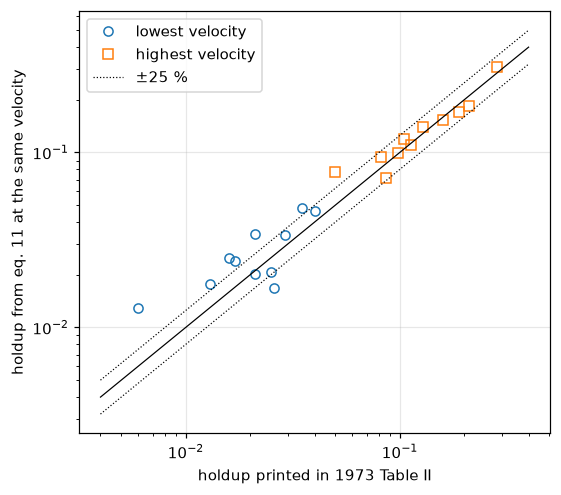

At the highest velocity of each row eq. 11 gives 1.039 times the printed holdup (geometric mean of 11 rows), from 0.828 to 1.541, with a mean absolute deviation of 13.3 %. At the lowest velocity the geometric mean is 1.232, from 0.647 to 2.152. Each end is one run, and the table does not say that the lowest holdup and the lowest velocity belong to the same run.

In [9]:
fig, ax = plt.subplots(figsize=(5.2, 4.6))
for end, mk in (("lo", "o"), ("hi", "s")):
    q = R[R.end == end]
    ax.loglog(q.eps_printed, q.eps_pred, mk, mfc="none",
              label="lowest velocity" if end == "lo" else "highest velocity")
lim = np.array([4e-3, 0.4])
ax.plot(lim, lim, "k-", lw=0.8)
ax.plot(lim, 1.25 * lim, "k:", lw=0.8)
ax.plot(lim, lim / 1.25, "k:", lw=0.8, label="±25 %")
ax.set_xlabel("holdup printed in 1973 Table II")
ax.set_ylabel("holdup from eq. 11 at the same velocity")
ax.legend()
plt.tight_layout()
plt.show()
say("At the highest velocity of each row eq. 11 gives <<g:.3f>> times the printed holdup "
    "(geometric mean of <<n:d>> rows), from <<lo:.3f>> to <<hi:.3f>>, with a mean absolute "
    "deviation of <<mad:pct1>>. At the lowest velocity the geometric mean is <<gl:.3f>>, "
    "from <<lol:.3f>> to <<hil:.3f>>. Each end is one run, and the table "
    "does not say that the lowest holdup and the lowest velocity belong to the same run.",
    g=M["eps_hi_geo_ratio"], n=M["n_matched_rows"], lo=M["eps_hi_min_ratio"],
    hi=M["eps_hi_max_ratio"], mad=M["eps_hi_mean_abs_dev"], gl=M["eps_lo_geo_ratio"],
    lol=M["eps_lo_min_ratio"], hil=M["eps_lo_max_ratio"])

### Does $k_L \times a$ give back $k_La$?

At each of those points the holdup from eq. 11 gives $k_La$ by the 1973 eq. 18, and
$d_{vs}$ (eq. 19), $a = 6\varepsilon_G/d_{vs}$ (eq. 21) and $k_L$ (eq. 32) give the
1974 product. Both use the same holdup, so only the correlations differ.

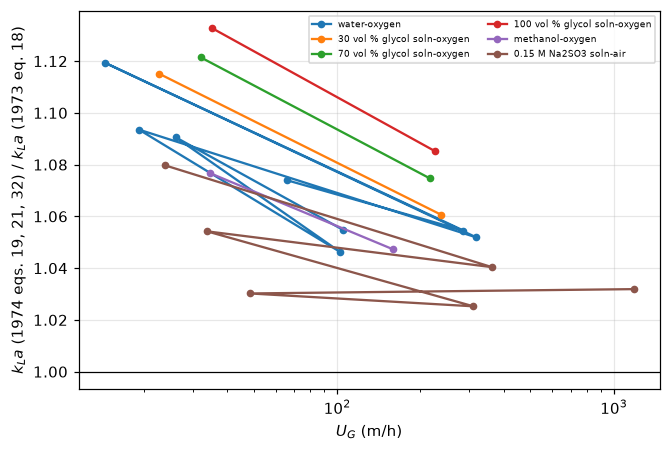

Over the 22 points the 1974 product is 1.071 times the 1973 $k_La$ (geometric mean), from 1.025 to 1.133. With eq. 24 for the area instead of $6\varepsilon_G/d_{vs}$ the geometric mean is 1.072.

In [10]:
fig, ax = plt.subplots(figsize=(6.2, 4.2))
for sys_, q in R.groupby("system", sort=False):
    ax.semilogx(q.UG * 3600, q.kla74 / q.kla73, "o-", label=sys_, ms=4)
ax.axhline(1, color="k", lw=0.8)
ax.set_xlabel("$U_G$ (m/h)")
ax.set_ylabel("$k_L a$ (1974 eqs. 19, 21, 32) / $k_L a$ (1973 eq. 18)")
ax.legend(fontsize=6, ncol=2)
plt.tight_layout()
plt.show()
say("Over the <<n:d>> points the 1974 product is <<g:.3f>> times the 1973 $k_La$ "
    "(geometric mean), from <<lo:.3f>> to <<hi:.3f>>. With eq. 24 for the area instead of "
    "$6\\varepsilon_G/d_{vs}$ the geometric mean is <<g24:.3f>>.",
    n=len(R), g=M["kla_product_geo_ratio"], lo=M["kla_product_min_ratio"],
    hi=M["kla_product_max_ratio"], g24=M["kla_product_eq24_geo_ratio"])

### The calculated and observed $k_La$ of the 1974 Figure 12

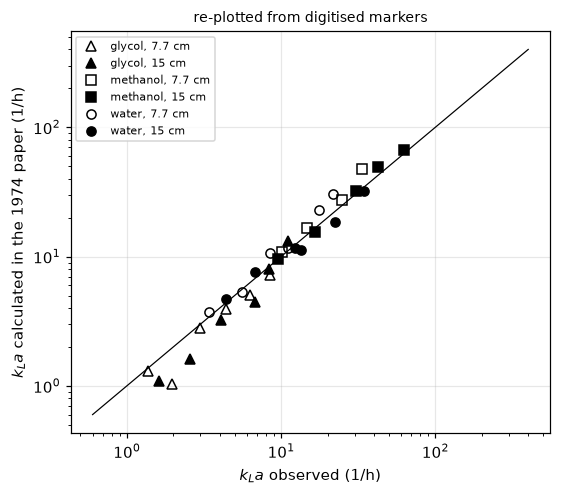

The 33 markers have a geometric-mean ratio calculated/observed of 0.964, 0.9 standard errors below 1, and a mean absolute deviation of 16.3 %; the largest deviation is -47.4 %. In the 7.7 cm column the ratio is 1.020, in the 15.0 cm column 0.914.

In [11]:
fig, ax = plt.subplots(figsize=(5.2, 4.6))
for (liq, Dc), q in C.f12.groupby(["liquid", "D_cm"]):
    mk = {"water": "o", "glycol": "^", "methanol": "s"}[liq]
    ax.loglog(q.kla_obs_per_h, q.kla_calc_per_h, mk, mfc="none" if Dc < 10 else None,
              color="k", label=f"{liq}, {Dc:g} cm")
lim = np.array([0.6, 400])
ax.plot(lim, lim, "k-", lw=0.8)
ax.set_xlabel("$k_La$ observed (1/h)")
ax.set_ylabel("$k_La$ calculated in the 1974 paper (1/h)")
ax.legend(fontsize=7)
ax.set_title("re-plotted from digitised markers", fontsize=9)
plt.tight_layout()
plt.show()
say("The <<n:d>> markers have a geometric-mean ratio calculated/observed of <<g:.3f>>, "
    "<<z:.1f>> standard errors <<side>> 1, and a mean absolute deviation of <<mad:pct1>>; the "
    "largest deviation is <<w:+pct1>>. In the 7.7 cm column the ratio is <<g7:.3f>>, in the "
    "15.0 cm column <<g15:.3f>>.",
    n=M["f12_n"], g=M["f12_geo_ratio"], z=abs(M["f12_bias_z"]),
    side="below" if M["f12_bias_z"] < 0 else "above", mad=M["f12_mean_abs_dev"],
    w=M["f12_worst_dev"], g7=M["f12_geo_ratio_D7"], g15=M["f12_geo_ratio_D15"])

## Validation

### 1. The exponents of the dimensional forms

Eq. 17 is eq. 18 written out in the physical quantities, and eq. 33 is eq. 32 so
written. Collecting the powers of $D_L$, $\nu_L$, $\gamma/\rho_L$, $D$ and $g$ (and of
$d_{vs}$, $\rho_L$, $\gamma$ for eq. 33) from the dimensionless exponents must give
the printed dimensional ones; the same bookkeeping on eq. 11 must give a zero power
of $D$, the property the 1973 exponents were chosen for.

In [12]:
say("Largest gap between a printed and a derived exponent: below 1e-12 for eq. 17 (here "
    "<<g17:.1e>>) and for eq. 33 (here <<g33:.1e>>). The power of $D$ in eq. 11 is zero to "
    "below 1e-12 (here <<hd:.1e>>). The printed exponents are exact "
    "consequences of the dimensionless ones; in particular $2p + 3q - 2 = <<d>>$ holds "
    "with $p = <<p>>$, $q = <<q>>$.",
    g17=M["eq17_exponent_gap"], g33=M["eq33_exponent_gap"], hd=abs(M["holdup_D_exponent"]),
    d=PRINTED["D_exp_kla"], p=PRINTED["p_Bo"], q=PRINTED["q_Ga"])

Largest gap between a printed and a derived exponent: below 1e-12 for eq. 17 (here 1.1e-16) and for eq. 33 (here 0.0e+00). The power of $D$ in eq. 11 is zero to below 1e-12 (here 0.0e+00). The printed exponents are exact consequences of the dimensionless ones; in particular $2p + 3q - 2 = 0.17$ holds with $p = 0.62$, $q = 0.31$.

### 2. Eq. 24 from eqs. 19, 21 and 23

Substituting eq. 23 for the Froude number in eq. 19 and dividing $6\varepsilon_G$ by
the result gives eq. 24 before simplification.

In [13]:
say("The combination gives $aD = <<c:.4f>>\\,N_{Bo}^{<<pb:.4f>>}N_{Ga}^{<<pg:.4f>>}"
    "\\varepsilon_G^{<<pe:.4f>>}$. The paper prints <<c24>>, <<p24>>, <<q24>> and <<e24>>: the "
    "exponents are rounded, and the printed coefficient is <<r:.3f>> times the one the "
    "three equations imply. On the Table II points the printed eq. 24 gives <<a:.3f>> times "
    "the area of eq. 21 with eq. 19 (from <<lo:.3f>> to <<hi:.3f>>); the unrounded "
    "combination gives <<ai:.3f>> times, which is the effect of eq. 23 standing in for "
    "eq. 11 alone. The rounding of the exponents therefore takes back most of what the "
    "rounded coefficient adds, on these points; it need not elsewhere.",
    c=M["eq24_implied_coef"], pb=M["eq24_implied_Bo_exp"], pg=M["eq24_implied_Ga_exp"],
    pe=M["eq24_implied_eps_exp"], r=M["eq24_coef_printed_over_implied"],
    c24=PRINTED["c_eq24"], p24=PRINTED["p_eq24"], q24=PRINTED["q_eq24"], e24=PRINTED["e_eq24"],
    a=M["a_eq24_over_eq21_geo"], lo=M["a_eq24_over_eq21_min"], hi=M["a_eq24_over_eq21_max"],
    ai=M["a_implied24_over_eq21_geo"])

The combination gives $aD = 0.2999\,N_{Bo}^{0.4850}N_{Ga}^{0.1100}\varepsilon_G^{1.1333}$. The paper prints 1/3, 0.5, 0.1 and 1.13: the exponents are rounded, and the printed coefficient is 1.111 times the one the three equations imply. On the Table II points the printed eq. 24 gives 1.001 times the area of eq. 21 with eq. 19 (from 0.897 to 1.074); the unrounded combination gives 0.995 times, which is the effect of eq. 23 standing in for eq. 11 alone. The rounding of the exponents therefore takes back most of what the rounded coefficient adds, on these points; it need not elsewhere.

### 3. Eq. 23 as a stand-in for eq. 11

For one holdup, the ratio of the Froude number eq. 11 needs to the one eq. 23 needs
depends on $\varepsilon_G$ alone when the Bond and Galilei exponents match, as they
do as printed. Its minimum is the root of its logarithmic derivative,
$(1 - 10/9)/\varepsilon + 4/(1-\varepsilon) = 0$; the crossings are roots on the range.

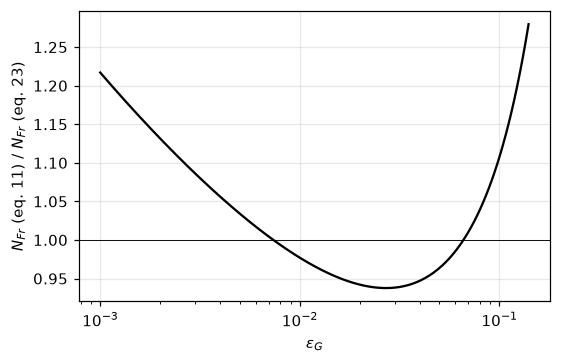

The ratio is 1 at $\varepsilon_G = 0.0074$ and 0.0660, has its minimum 0.938 at $\varepsilon_G = 0.0270$, and reaches 1.280 at the stated limit 0.14. Eq. 23 is within 10 % of eq. 11 only for $0.0026 < \varepsilon_G < 0.0979$; over the upper part of the range the paper gives it, it asks for a velocity up to 22 % lower than eq. 11 for the same holdup.

The minimum lies 0.029 above 1/1.1, so the ratio never falls more than 10 % below 1.

In [14]:
ee = np.geomspace(1e-3, K["eps_max_eq23"], 300)
rho_, nu_, gam_, DL_ = si_props(C.props, "water_20")
Bo_, Ga_ = groups(0.152, rho_, nu_, gam_, C.g)
ratio_ = (ee / (1 - ee)**4 / (K["c1"] * Bo_**K["a_Bo"] * Ga_**K["b_Ga"])
          / (K["c_eq23"] * Bo_**K["a_eq23"] * Ga_**K["b_eq23"] * ee**K["e_eq23"]))
fig, ax = plt.subplots(figsize=(5.2, 3.4))
ax.semilogx(ee, ratio_, "k-")
ax.axhline(1, color="k", lw=0.6)
ax.set_xlabel(r"$\varepsilon_G$")
ax.set_ylabel(r"$N_{Fr}$ (eq. 11) / $N_{Fr}$ (eq. 23)")
plt.tight_layout()
plt.show()
say("The ratio is 1 at $\\varepsilon_G = <<a:.4f>>$ and <<b:.4f>>, has its minimum "
    "<<m:.3f>> at $\\varepsilon_G = <<e:.4f>>$, and reaches <<x:.3f>> at the stated limit "
    "<<emax>>. Eq. 23 is within 10 % of eq. 11 only for $<<tl:.4f>> < \\varepsilon_G < "
    "<<t:.4f>>$; over the upper part of the range the paper gives it, it asks for a "
    "velocity up to <<xp:pct0>> lower than eq. 11 for the same holdup.",
    a=M["eq23_eps_lower_crossing"], b=M["eq23_eps_upper_crossing"], m=M["eq23_ratio_min"],
    e=M["eq23_eps_at_min"], t=M["eq23_eps_where_10pct"], x=M["eq23_ratio_at_eps_max"],
    tl=M["eq23_eps_where_10pct_low"], emax=PRINTED["eps_max_eq23"],
    xp=1 - 1 / M["eq23_ratio_at_eps_max"])
say("The minimum lies <<mg:.3f>> above 1/1.1, so the ratio never falls more than 10 % "
    "below 1.", mg=M["eq23_ratio_min_margin"])

### 4. For scale: the holdup correlations of F1.4 and F1.3

The neighbouring pages measure a holdup correlation against its own figure. Their
committed numbers are read with `load_claims`, not retyped. The data differ
(large-bubble holdup in tetradecane against total holdup in aqueous liquids), so
this is a scale, not a ranking.

In [15]:
F14C, F13C = load_claims(F14), load_claims(F13)
M["eps_hi_mad_over_F14_eq19"] = M["eps_hi_mean_abs_dev"] / F14C["eq19_mean_abs_dev"]
M["eps_hi_mad_over_F13_wilkinson"] = M["eps_hi_mean_abs_dev"] / F13C["wilkinson_eps_b_mean_abs_dev"]
display(pd.DataFrame({
    "correlation": ["Akita-Yoshida eq. 11, highest-velocity ends of 1973 Table II (this page)",
                    "Krishna-Ellenberger eq. 19, Figure 11 markers (F1.4)",
                    "Wilkinson et al., the same markers (F1.3)"],
    "mean absolute deviation": [f"{v:.1%}" for v in (M["eps_hi_mean_abs_dev"],
                                F14C["eq19_mean_abs_dev"],
                                F13C["wilkinson_eps_b_mean_abs_dev"])]}).set_index("correlation"))
say("The Akita-Yoshida deviation here is <<a:.2f>> times that of eq. 19 on F1.4 and "
    "<<b:.2f>> times that of Wilkinson on F1.3.",
    a=M["eps_hi_mad_over_F14_eq19"], b=M["eps_hi_mad_over_F13_wilkinson"])

,mean absolute deviation
correlation,
"Akita-Yoshida eq. 11, highest-velocity ends of 1973 Table II (this page)",13.3%
"Krishna-Ellenberger eq. 19, Figure 11 markers (F1.4)",13.8%
"Wilkinson et al., the same markers (F1.3)",63.9%


The Akita-Yoshida deviation here is 0.96 times that of eq. 19 on F1.4 and 0.21 times that of Wilkinson on F1.3.

## What pymrm adds

Nothing to the correlations: the page is algebra and calls no pymrm operator. pymrm
contributes `pymrm.checks.find_roots`, which solves the implicit holdup of eq. 11 at
every point and locates the minimum and the crossings of eq. 23 against eq. 11 as
bracketed roots on the whole range, raising when the count is not one. What the
page adds to the papers is a set of checks they do not print: their two tables
against each other, the 1974 pieces multiplied back against the 1973 product, the
rounding inside eq. 24, the range over which eq. 23 is a fair stand-in for eq. 11,
and the scatter of their own Figure 12 as a number.

## Reuse

- The functions `holdup_eq11`, `kla_eq18`, `dvs_eq19`, `kl_eq32` and `a_eq24` take SI
  arguments and the dictionary `K`, and can be lifted into a reactor model as
  closures for holdup and mass transfer.
- For $k_La$, eq. 18 and the product of eqs. 19, 21 and 32 are not the same
  correlation: the ratio printed in Results is the size of the choice. Use one
  consistently. Prefer eq. 21 with eq. 19 for the area: eq. 24 agrees with it on
  the Table II points only because two roundings nearly cancel (Validation 2).
- Use eq. 11 itself rather than eq. 23 outside the holdup window of Validation 3.
- The 1973 paper suggests the larger coefficient for electrolyte solutions; the page
  applies it to the sulfite rows only.
- Correlated range: the column diameters, velocities and liquids of the 1973 Table II
  and the two property tables. For columns wider than those tested, the 1973 paper
  advises taking the $k_La$ of its widest column.

### The break table

Every number registered below has a row that moves it. Each row mistypes one
published constant, or changes one input of the data, and reruns the whole study;
the claims it fails are counted. A row under which one of the root searches no
longer finds exactly one root makes the study raise; such a row records nan, which
catches no claim, so every claim also has a row that moves it to a finite value
(the counts of table entries and the worst Table IV class by a dropped table row).
The controls fail nothing.

In [16]:
RTOL = 1e-6
STRUCTURAL = {"t4_lognormal_dvs_identity"}
SPECIAL_EXACT = {"t4_n_total", "t4_entries", "fr_entries", "grp_entries", "n_matched_rows",
                 "f12_n", "t4_worst_dmu3_class", "t4_worst_dF_class"}
COUNTS = {"t4_entries_off": 0.02, "t4_entries_off_three_units": 0.02, "fr_entries_off": 0.02,
          "grp_entries_off_half": 0.02, "grp_entries_off_two": 0.02}
IDENTITY = {"eq17_exponent_gap", "eq33_exponent_gap", "holdup_D_exponent", "t4_n_total_gap"}
for name, v in M.items():
    if name.endswith("__margin"):
        continue
    if name in STRUCTURAL:
        claims.bound(name, v, max=1e-12, basis="identity", structural=True,
                     note="m and sigma are solved from mu2 and mu3, so exp(m + 2.5 sigma^2) = mu3/mu2")
    elif name in IDENTITY:
        claims.bound(name, abs(v), max=1e-12, basis="identity",
                     note="printed exponents (or count) against the ones derived from the paper's own equations")
    elif name in SPECIAL_EXACT:
        claims.exact(name, v)
    elif name in COUNTS:
        claims.exact(name, v, margin=M[name + "__margin"], min_margin=COUNTS[name])
    else:
        claims.value(name, v, rtol=RTOL)

In [17]:
BREAK_K = [k for k in K if not k.startswith("t4_D") and not k.startswith("t4_UG")]


def mistyped(name):
    v = K[name] * 1.1 if K[name] != 0 else 0.1
    return f"{name} {PRINTED[name]} -> {v:.6g}", {**K, name: v}, C


def scaled_prop(col, key, f):
    p = C.props.copy()
    p.loc[p.key == key, col] = p.loc[p.key == key, col] * f
    return f"{col} of {key} x {f:g}", K, replace(C, props=p)


def t4_change(col, i, new):
    t = C.t4.copy()
    old = t.loc[i, col]
    t.loc[i, col] = new
    return f"Table IV {col} row {i}: {old} -> {new}", K, replace(C, t4=t)


def t2_change(col, i, new):
    t = C.t2.copy()
    old = t.loc[i, col]
    t.loc[i, col] = new
    return f"1973 Table II {col} row {i}: {old} -> {new}", K, replace(C, t2=t)


def t4_drop(i):
    t = C.t4.drop(index=i).reset_index(drop=True)
    return f"Table IV row {i} ({C.t4.range_mm[i]} mm) dropped", K, replace(C, t4=t)


def t2_drop(i):
    t = C.t2.drop(index=i).reset_index(drop=True)
    return (f"1973 Table II row {i} ({C.t2.system[i]}, {C.t2.temp_C[i]} C) dropped", K,
            replace(C, t2=t))


def f12_scaled(col, f):
    t = C.f12.copy()
    t[col] = t[col] * f
    return f"Figure 12 {col} x {f:g}", K, replace(C, f12=t)


def f12_drop(i):
    return f"Figure 12 marker {i} dropped", K, replace(C, f12=C.f12.drop(index=i).reset_index(drop=True))


def f12_relabel(i):
    t = C.f12.copy()
    old = t.loc[i, "D_cm"]
    t.loc[i, "D_cm"] = 15.0 if old < 10 else 7.7
    return f"Figure 12 marker {i} column {old:g} -> {t.loc[i, 'D_cm']:g} cm", K, replace(C, f12=t)


DEFECTS = [mistyped(k) for k in BREAK_K] + [
    ("gravity 9.81 -> 9.7", K, replace(C, g=9.7)),
    scaled_prop("density_g_cm3", "water_20", 1.02),
    scaled_prop("viscosity_cP", "water_20", 1.05),
    scaled_prop("surface_tension_dyn_cm", "methanol_22", 1.05),
    scaled_prop("diffusivity_O2_1e-5_cm2_s", "glycol_70", 1.05),
    scaled_prop("viscosity_cP", "glycol_100", 1.05),
    t4_change("n_bubbles", 3, "462"), t4_change("x_mm", 10, "12.8"),
    t4_change("dF_pct", 5, "15.25"), t4_change("F_pct", 5, "79.54"),
    t4_change("dmu2_mm2", 8, "2.245"), t4_change("dmu3_mm3", 8, "15.70"),
    t2_change("D_cm", 0, "15.6"), t2_change("UG_hi_m_h", 1, "339"),
    t2_change("UG_lo_m_h", 8, "24.7"), t2_change("eps_hi", 12, "0.220"),
    t2_change("eps_lo", 10, "0.022"), t2_change("NFr_lo_e3", 3, "4.3"),
    t2_change("NBo_em3", 11, "8.12"), t2_change("NGa_em10", 8, "0.646"),
    t2_change("NSc_em3", 9, "11.3"), t2_change("eps_lo", 1, "0.007"),
    t4_drop(10), t2_drop(1),
    f12_scaled("kla_obs_per_h", 1.05), f12_scaled("kla_calc_per_h", 1.05),
    f12_drop(0), f12_drop(32), f12_relabel(0),
]
CONTROLS = [("control: clean rerun", K, C),
            ("control: Figure 12 markers in reverse order", K,
             replace(C, f12=C.f12.iloc[::-1].reset_index(drop=True)))]
claims.define_rows([r_ for r_, _, _ in CONTROLS + DEFECTS])
BREAK = []
for row, k_, c_ in CONTROLS + DEFECTS:
    try:
        Mb = study(k_, c_)
        Mb.pop("_R")
    except ValueError:
        Mb = {}
    Mb["eps_hi_mad_over_F14_eq19"] = Mb.get("eps_hi_mean_abs_dev", np.nan) / F14C["eq19_mean_abs_dev"]
    Mb["eps_hi_mad_over_F13_wilkinson"] = (Mb.get("eps_hi_mean_abs_dev", np.nan)
                                           / F13C["wilkinson_eps_b_mean_abs_dev"])
    for name in claims.metrics:
        v = Mb.get(name, np.nan)
        if name in IDENTITY:
            v = abs(v)
        BREAK.append((row, name, claims.breaks(row, name, v)))

In [18]:
# The break table: one line per row, with the claims it fails.
by_row = {}
for r_, m_, c_ in BREAK:
    by_row.setdefault(r_, []).append(c_)
_bad = [r_ for r_ in by_row if r_.startswith("control") and any(by_row[r_])]
assert not _bad, f"a control row failed a claim: {_bad}"
print(f"{'injected defect':<60} {'claims failed':>13}")
for r_, cs in by_row.items():
    print(f"{r_[:60]:<60} {sum(cs):13d}")
_caught = {m_ for _, m_, c_ in BREAK if c_}
_open = sorted(k_ for k_ in claims.metrics if k_ not in _caught
               and not claims.metrics[k_].get("structural"))
print(f"\n{len(by_row)} rows; {len(_caught)} of {len(claims.metrics)} claims are failed by at "
      f"least one row; open: {', '.join(_open) or 'none'}")

injected defect                                              claims failed
control: clean rerun                                                     0
control: Figure 12 markers in reverse order                              0
c1 0.20 -> 0.22                                                         22
c1_electrolyte 0.25 -> 0.275                                            11
a_Bo 1/8 -> 0.1375                                                      25
b_Ga 1/12 -> 0.0916667                                                  75
holdup_power 4 -> 4.4                                                   25
c2 0.6 -> 0.66                                                           4
sc_exp 0.5 -> 0.55                                                       5
p_Bo 0.62 -> 0.682                                                       5
q_Ga 0.31 -> 0.341                                                       5
eps_exp 1.1 -> 1.21                                                      4
D_exp_kla 0.17 -> 0.187  

In [19]:
# Claims: prints every registered number, writes agreement.json for CI, and
# raises when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for F1.1:
  t4_n_total                     = 3161             exact  exact
  t4_mu2                         = 16.27            value  rtol 1e-06
  t4_mu3                         = 150.4            value  rtol 1e-06
  t4_dvs_mm                      = 9.2441           value  rtol 1e-06
  t4_dg_mm                       = 2.3205           value  rtol 1e-06
  t4_sigma                       = 0.74356          value  rtol 1e-06
  t4_lognormal_dvs_identity      = (here 0.0e+00)   bound  bound <= 1e-12 [identity]
  t4_entries                     = 68               exact  exact
  t4_entries_off                 = 4                exact  exact, margin 0.042
  t4_entries_off_three_units     = 1                exact  exact, margin 0.385
  t4_worst_dmu3_class            = '10.1-15.0'      exact  exact
  t4_worst_dmu3_computed         = 23.548           value  rtol 1e-06
  t4_worst_dmu3_printed          = 25.54            value  rtol 1e-06
  t4_worst_dF_class              = '6.1-8.0'        exa